# Orkanen Gabrielle
## Fra varmemaskin til ekstratropisk storm

Gabrielle ble dannet i det tropiske Atlanterhavet 17. september 2025. Fem dager senere var den en kategori 4-orkan øst for Bermuda. Natt til 26. september traff den Asorene, men da var den ikke lenger en tropisk syklon. Likevel målte stasjonene på øyene vindkast av orkanstyrke.

I denne økten bruker du ekte måledata til å svare på hovedspørsmålet nedenfor.

> 🌀 **Hovedspørsmål**
> Hvorfor ble Gabrielle så sterk så raskt, hvorfor svekket den seg igjen, og hvordan kunne Asorene få orkankast fra en storm som ikke lenger var en orkan?

| Tid | Del |
|---|---|
| 0–10 min | Oppstart og hypotese |
| 10–35 min | Del 1 Banen og styrken |
| 35–60 min | Del 2 Havet som drivstoff |
| 60–70 min | Pause |
| 70–100 min | Del 3 Fra orkan til ekstratropisk storm |
| 100–120 min | Del 4 Oppsummering |

**Slik jobber du**
- Kjør cellene i rekkefølge med Shift + Enter.
- Svar i cellene merket ✏️. Dobbeltklikk for å skrive, og trykk Shift + Enter når du er ferdig.
- I cellene merket 🔧 skal du endre en verdi selv og kjøre cellen på nytt.
- Har du tid til overs, finner du to fordypningsoppgaver helt til slutt.

### Oppstart
Før du ser på dataene. Skriv en hypotese om hvorfor en storm kan gi orkankast selv om den ikke lenger er en tropisk syklon.

✏️ **Svar**

*Min hypotese er at …*

### Last inn verktøy og data
Kjør cellen nedenfor. Den henter inn Python-pakkene og leser datafilene i mappen `data`. Les meldingene som skrives ut.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature

DATA = Path("data")
KT_TIL_MS = 1852 / 3600          # 1 knop = 1 nautisk mil (1852 m) per time
PC = ccrs.PlateCarree()           # koordinatene i dataene er lengde- og breddegrad
PROJ = ccrs.LambertConformal(central_longitude=-40, standard_parallels=(25, 45))

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})

# Saffir–Simpson-skalaen i m/s (Store norske leksikon), 1-minutts middelvind
SS_GRENSER = [0, 17, 33, 43, 50, 58, 70, 90]
SS_NAVN = ["Trop. depresjon", "Trop. storm", "Kat. 1", "Kat. 2",
           "Kat. 3", "Kat. 4", "Kat. 5"]
SS_FARGER = ListedColormap(["#c6dbef", "#9ecae1", "#fed976", "#feb24c",
                            "#fd8d3c", "#e31a1c", "#800026"])


def komma(ax, x=False, y=True):
    """Desimalkomma og ekte minus på aksene."""
    f = mticker.FuncFormatter(lambda v, p: f"{v:g}".replace(".", ",").replace("-", "−"))
    if x:
        ax.xaxis.set_major_formatter(f)
    if y:
        ax.yaxis.set_major_formatter(f)


def datoakse(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))


def kart(ax, utsnitt):
    """Kartbakgrunn med land, kystlinje og gradnett med norske retninger."""
    ax.set_extent(utsnitt, crs=PC)
    ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=2)
    ax.coastlines(resolution="50m", lw=0.6, color="0.3", zorder=3)
    gl = ax.gridlines(draw_labels=True, x_inline=False, y_inline=False,
                      lw=0.4, color="0.5", ls=":")
    gl.top_labels = gl.right_labels = False
    gl.xformatter = mticker.FuncFormatter(
        lambda v, p=None: "0°" if v == 0 else f"{abs(v):.0f}° {'V' if v < 0 else 'Ø'}")
    gl.yformatter = mticker.FuncFormatter(lambda v, p=None: f"{v:.0f}° N")


def avstand_km(lat1, lon1, lat2, lon2):
    """Avstand langs jordoverflaten (km) mellom punkter gitt i grader."""
    R = 6371.0
    f1, f2 = np.radians(lat1), np.radians(lat2)
    dl = np.radians(np.asarray(lon2) - np.asarray(lon1))
    df = f2 - f1
    a = np.sin(df / 2) ** 2 + np.cos(f1) * np.cos(f2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


def finnes(fil):
    if (DATA / fil).exists():
        return True
    print(f"⚠️  Finner ikke {fil} i mappen data. Spør læreren.")
    return False


# --- Banedata -------------------------------------------------------------
if (DATA / "gabrielle_bane.csv").exists():
    bane = pd.read_csv(DATA / "gabrielle_bane.csv", parse_dates=["tid_utc"])
    BANEKILDE = "Kilde: IBTrACS v04r01 (NOAA NCEI), beste estimat fra NHC"
else:
    bane = pd.read_csv(DATA / "gabrielle_bane_nhc_tabell1_utdrag.csv",
                       parse_dates=["tid_utc"])
    BANEKILDE = "Kilde: NHC Tropical Cyclone Report, tabell 1 (fra 21. september)"
    print("ℹ️  Bruker utdraget fra NHC-rapporten. Banen starter 21. september.")

bane = bane.dropna(subset=["vind_kt"]).sort_values("tid_utc").reset_index(drop=True)
bane["vind_ms"] = bane["vind_kt"] * KT_TIL_MS
bane["tropisk"] = bane["status"].isin(["TD", "TS", "HU", "SD", "SS"])
print(f"Banedata: {len(bane)} tidspunkter fra {bane.tid_utc.min():%d.%m %H} UTC "
      f"til {bane.tid_utc.max():%d.%m %H} UTC")

# --- Havtemperatur, ERA5 og stasjoner --------------------------------------
sst = xr.open_dataset(DATA / "oisst_gabrielle.nc").sst if finnes("oisst_gabrielle.nc") else None
era5 = xr.open_dataset(DATA / "era5_bakke.nc") if finnes("era5_bakke.nc") else None
era5p = xr.open_dataset(DATA / "era5_trykkflater.nc") if finnes("era5_trykkflater.nc") else None
stasjoner = pd.read_csv(DATA / "asorene_stasjoner_gabrielle.csv",
                        dtype={"wmo_id": str},
                        parse_dates=["tid_min_trykk_utc", "tid_maks_vind_utc"])
print("Klar ✅")

Banedata: 45 tidspunkter fra 17.09 18 UTC til 28.09 18 UTC


/Users/Elisabeth.Merete.Engum/miniconda3/envs/geofag2/bin/python: No module named pip


Klar ✅


In [2]:
bane.head(8)

,tid_utc,lat,lon,vind_kt,trykk_hPa,status,fart_kt,retning_grader,rmw_nmi,vind_ms,tropisk
0,2025-09-17 18:00:00,19.0,-47.7,45.0,1005.0,TS,12,285,130.0,23.15,True
1,2025-09-18 00:00:00,19.3,-48.9,45.0,1004.0,TS,11,285,130.0,23.15,True
2,2025-09-18 06:00:00,19.6,-50.0,45.0,1004.0,TS,11,285,130.0,23.15,True
3,2025-09-18 12:00:00,20.0,-51.2,45.0,1004.0,TS,11,295,150.0,23.15,True
4,2025-09-18 18:00:00,20.5,-52.2,45.0,1004.0,TS,10,300,150.0,23.15,True
5,2025-09-19 00:00:00,21.0,-53.1,45.0,1004.0,TS,10,295,130.0,23.15,True
6,2025-09-19 06:00:00,21.4,-54.1,45.0,1004.0,TS,10,290,130.0,23.15,True
7,2025-09-19 12:00:00,21.7,-55.1,45.0,1004.0,TS,10,290,130.0,23.15,True


Tabellen ovenfor viser de første radene i banedataene. Hver rad er ett tidspunkt med seks timers mellomrom. `vind_kt` er sterkeste middelvind over ett minutt i knop, og `trykk_hPa` er laveste lufttrykk i sentrum. I `status` betyr TS tropisk storm, HU orkan og EX ekstratropisk.

> 📘 **Begrep** **Knop** er en nautisk mil (1852 m) per time. 1 knop er omtrent 0,51 m/s. Vi regner om til m/s i alle figurene.

---
## Del 1 Banen og styrken (25 min)

### 1a Hvor gikk Gabrielle?
Kartet nedenfor viser banen. Fargen viser kategorien på Saffir–Simpson-skalaen. Runde punkter er tropisk syklon, kryss er ekstratropisk lavtrykk.

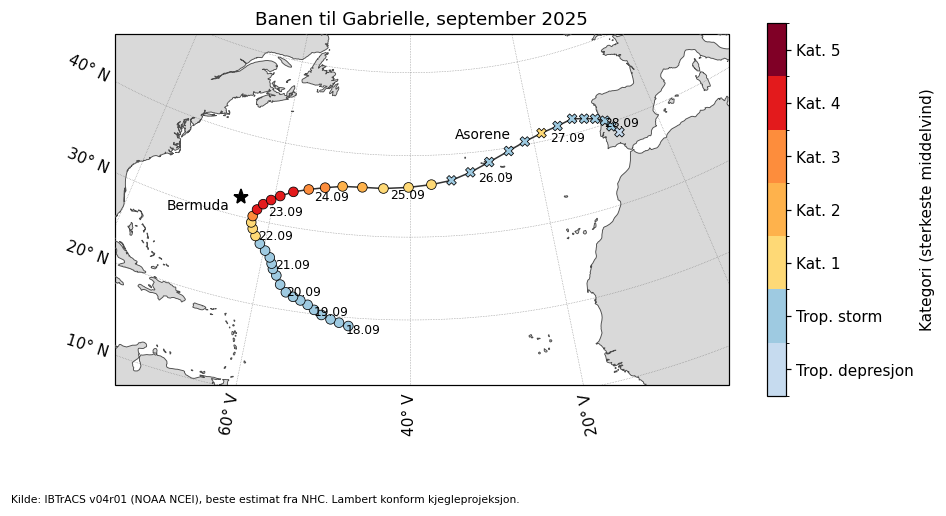

In [3]:
fig = plt.figure(figsize=(9, 5.5))
ax = plt.axes(projection=PROJ)
kart(ax, [-75, -2, 12, 50])

ax.plot(bane.lon, bane.lat, color="0.2", lw=1, transform=PC, zorder=4)
norm = BoundaryNorm(SS_GRENSER, SS_FARGER.N)
for tropisk, merke in [(True, "o"), (False, "X")]:
    b = bane[bane.tropisk == tropisk]
    sc = ax.scatter(b.lon, b.lat, c=b.vind_ms, cmap=SS_FARGER, norm=norm, s=40,
                    marker=merke, edgecolor="k", lw=0.5, transform=PC, zorder=5)

# Dato ved hvert døgnskifte
for _, r in bane[bane.tid_utc.dt.hour == 0].iterrows():
    ax.text(r.lon + 1, r.lat - 1.2, f"{r.tid_utc:%d.%m}", fontsize=8,
            transform=PC, zorder=6)

ax.plot(-64.8, 32.3, marker="*", color="k", ms=10, transform=PC, zorder=6)
ax.text(-66, 30.5, "Bermuda", fontsize=9, transform=PC, ha="right")
ax.text(-28, 41.5, "Asorene", fontsize=9, transform=PC, ha="center")

cb = fig.colorbar(sc, ax=ax, shrink=0.8, ticks=[(a + b) / 2 for a, b in zip(SS_GRENSER[:-1], SS_GRENSER[1:])])
cb.ax.set_yticklabels(SS_NAVN)
cb.set_label("Kategori (sterkeste middelvind)")
ax.set_title("Banen til Gabrielle, september 2025")
fig.text(0.02, 0.01, BANEKILDE + ". Lambert konform kjegleprojeksjon.", fontsize=7)
plt.show()

**Oppgaver**
1. Beskriv banen. I hvilken retning beveget Gabrielle seg de første dagene, og i hvilken retning etter 23. september?
2. Forklar hvorfor banen bøyer av mot nordøst. Tenk på det subtropiske høytrykket over Atlanterhavet og vestavindsbeltet lenger nord.
3. Se på avstanden mellom punktene. Hva forteller den om farten til stormen de siste dagene?

✏️ **Svar**

*Skriv svaret ditt her.*

### 1b Vind og trykk over tid

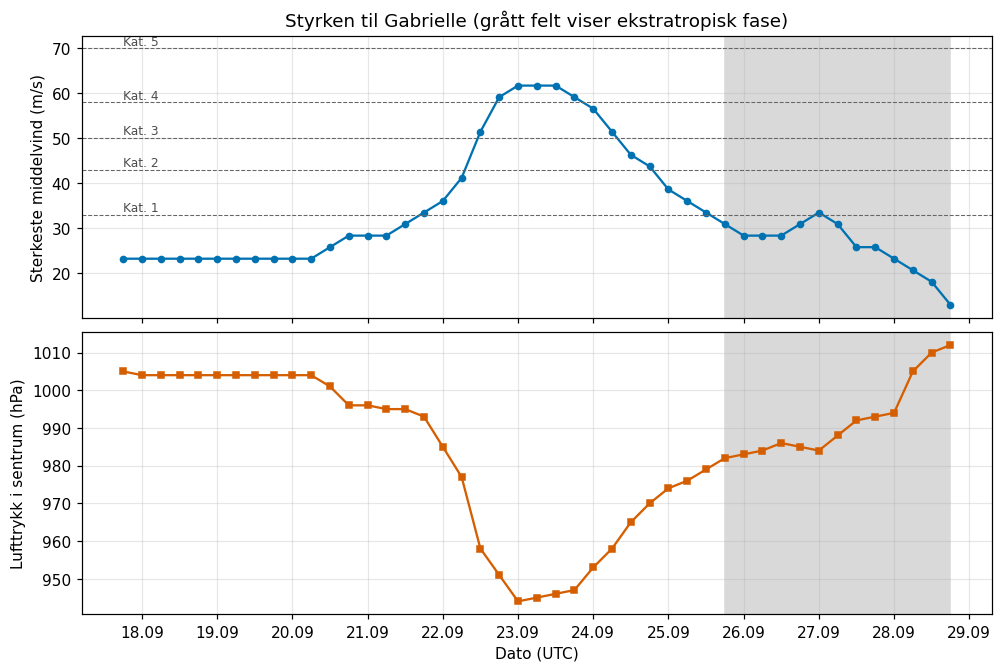

Sterkest 23.09 kl. 00 UTC med 62 m/s og 944 hPa


In [4]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)

ekstra = bane[~bane.tropisk]
for a in (a1, a2):
    if not ekstra.empty:
        a.axvspan(ekstra.tid_utc.min(), bane.tid_utc.max(), color="0.85", zorder=0)

a1.plot(bane.tid_utc, bane.vind_ms, "-o", color="#0072B2", ms=4)
for g, navn in zip(SS_GRENSER[2:-1], SS_NAVN[2:]):
    a1.axhline(g, color="0.4", ls="--", lw=0.7)
    a1.text(bane.tid_utc.min(), g + 0.8, navn, fontsize=8, color="0.3")
a1.set_ylabel("Sterkeste middelvind (m/s)")
a1.set_title("Styrken til Gabrielle (grått felt viser ekstratropisk fase)")

a2.plot(bane.tid_utc, bane.trykk_hPa, "-s", color="#D55E00", ms=4)
a2.set_ylabel("Lufttrykk i sentrum (hPa)")
a2.set_xlabel("Dato (UTC)")
datoakse(a2)
komma(a1); komma(a2)
plt.show()

topp = bane.loc[bane.vind_ms.idxmax()]
print(f"Sterkest {topp.tid_utc:%d.%m kl. %H} UTC med {topp.vind_ms:.0f} m/s "
      f"og {topp.trykk_hPa:.0f} hPa")

**Oppgaver**
1. Når var Gabrielle sterkest, og hvilken kategori nådde den?
2. Sammenlign de to kurvene. Hvordan henger lufttrykket i sentrum sammen med vindstyrken? Forklar med trykkgradientkraften.
3. Se på den grå fasen. Skjer det noe med vinden etter at stormen er blitt ekstratropisk?

✏️ **Svar**

*Skriv svaret ditt her.*

### 1c Rask intensivering

> 📘 **Begrep** **Rask intensivering** betyr at sterkeste middelvind øker med minst 30 knop (omtrent 15 m/s) på 24 timer. Rask intensivering er vanskelig å varsle og farlig fordi folk får kort tid til å forberede seg.

Cellen nedenfor regner ut hvor mye vinden har økt de siste 24 timene ved hvert tidspunkt.

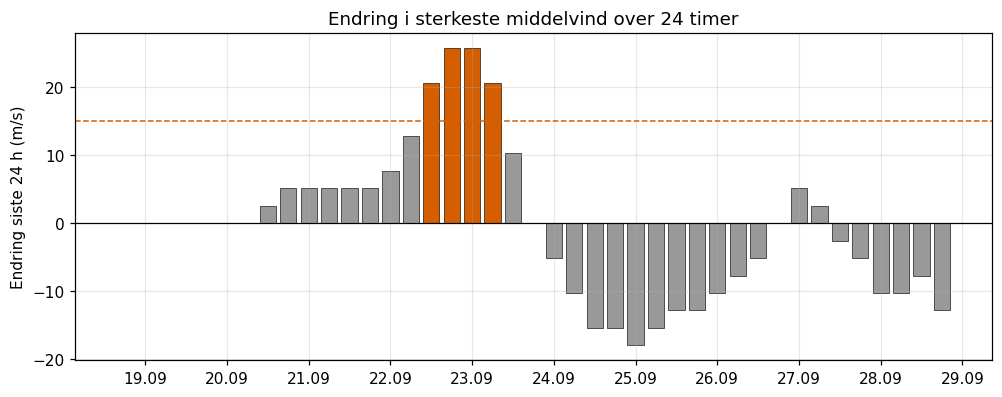

Tidspunkter med rask intensivering
tid_utc
2025-09-22 12:00:00    20.6
2025-09-22 18:00:00    25.7
2025-09-23 00:00:00    25.7
2025-09-23 06:00:00    20.6


In [5]:
TERSKEL = 15      # 🔧 m/s per 24 timer

s = bane.set_index("tid_utc")["vind_ms"]
endring = (s - s.shift(freq="24h")).dropna()

fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
farger = np.where(endring >= TERSKEL, "#D55E00", "0.6")
ax.bar(endring.index, endring.values, width=0.2, color=farger, edgecolor="k", lw=0.4)
ax.axhline(TERSKEL, color="#D55E00", ls="--", lw=1)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Endring siste 24 h (m/s)")
ax.set_title("Endring i sterkeste middelvind over 24 timer")
datoakse(ax); komma(ax)
plt.show()

print("Tidspunkter med rask intensivering")
print(endring[endring >= TERSKEL].round(1).to_string())

**Oppgaver**
1. I hvilket tidsrom gjennomgikk Gabrielle rask intensivering, og hva var den største økningen på 24 timer?
2. Hvor på kartet i 1a skjedde det?

✏️ **Svar**

*Skriv svaret ditt her.*

### 1d Trykk og vind

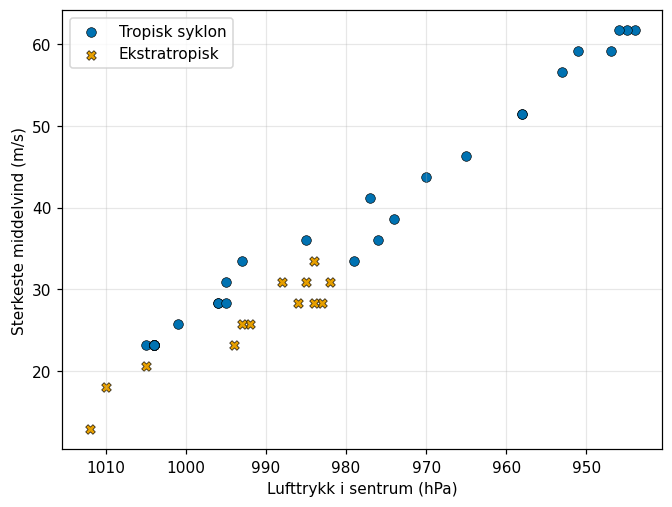

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
for tropisk, merke, farge, navn in [(True, "o", "#0072B2", "Tropisk syklon"),
                                    (False, "X", "#E69F00", "Ekstratropisk")]:
    b = bane[bane.tropisk == tropisk]
    ax.scatter(b.trykk_hPa, b.vind_ms, marker=merke, color=farge, s=40,
               edgecolor="k", lw=0.4, label=navn)
ax.set_xlabel("Lufttrykk i sentrum (hPa)")
ax.set_ylabel("Sterkeste middelvind (m/s)")
ax.invert_xaxis()
ax.legend()
komma(ax, x=True)
plt.show()

**Oppgaver**
1. Beskriv sammenhengen mellom trykk og vind for den tropiske fasen.
2. Finn et ekstratropisk punkt og et tropisk punkt med omtrent samme trykk. Hvilket har sterkest vind? Hva kan det fortelle om hvor stort og bratt trykkfeltet er i de to fasene?

✏️ **Svar**

*Skriv svaret ditt her.*

---
## Del 2 Havet som drivstoff (25 min)

En tropisk syklon er en varmemaskin. Den henter energi fra havet gjennom fordampning. Når vanndampen kondenserer i skyene, frigjøres latent varme som holder stormen i gang.

> 📘 **Begrep** Tropiske sykloner trenger vanligvis en **havtemperatur i overflaten** på minst **26,5 °C**, og varmt vann ned til omtrent 50 meters dyp.

### 2a Havtemperaturen før stormen

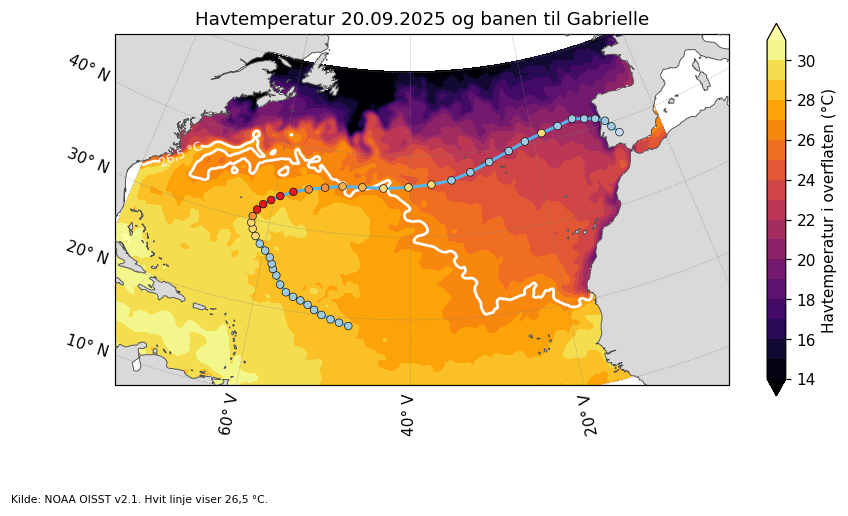

In [7]:
DATO_KART = "2025-09-20"      # 🔧 prøv også en dato etter at stormen har passert

if sst is not None:
    felt = sst.sel(time=DATO_KART, method="nearest")
    fig = plt.figure(figsize=(9, 5.5))
    ax = plt.axes(projection=PROJ)
    kart(ax, [-75, -2, 12, 50])
    cf = ax.contourf(felt.lon, felt.lat, felt, levels=np.arange(14, 32, 1),
                     cmap="inferno", extend="both", transform=PC)
    cs = ax.contour(felt.lon, felt.lat, felt, levels=[26.5], colors="w",
                    linewidths=1.8, transform=PC)
    ax.clabel(cs, fmt="26,5 °C", fontsize=8)
    ax.plot(bane.lon, bane.lat, color="#56B4E9", lw=2, transform=PC, zorder=4)
    ax.scatter(bane.lon, bane.lat, c=bane.vind_ms, cmap=SS_FARGER,
               norm=BoundaryNorm(SS_GRENSER, SS_FARGER.N), s=25,
               edgecolor="k", lw=0.4, transform=PC, zorder=5)
    fig.colorbar(cf, ax=ax, shrink=0.8, label="Havtemperatur i overflaten (°C)")
    ax.set_title(f"Havtemperatur {pd.Timestamp(felt.time.values):%d.%m.%Y} og banen til Gabrielle")
    fig.text(0.02, 0.01, "Kilde: NOAA OISST v2.1. Hvit linje viser 26,5 °C.", fontsize=7)
    plt.show()

**Oppgaver**
1. Hvor langt nord ligger 26,5 °C-linjen ved banen?
2. Var Gabrielle over vann varmere enn 26,5 °C da den gjennomgikk rask intensivering?

✏️ **Svar**

*Skriv svaret ditt her.*

### 2b Havtemperaturen under stormen

Cellen nedenfor finner havtemperaturen i hvert banepunkt **to døgn før** stormen kom dit. Da måler vi vannet stormen møtte, før den selv rakk å kjøle det ned.

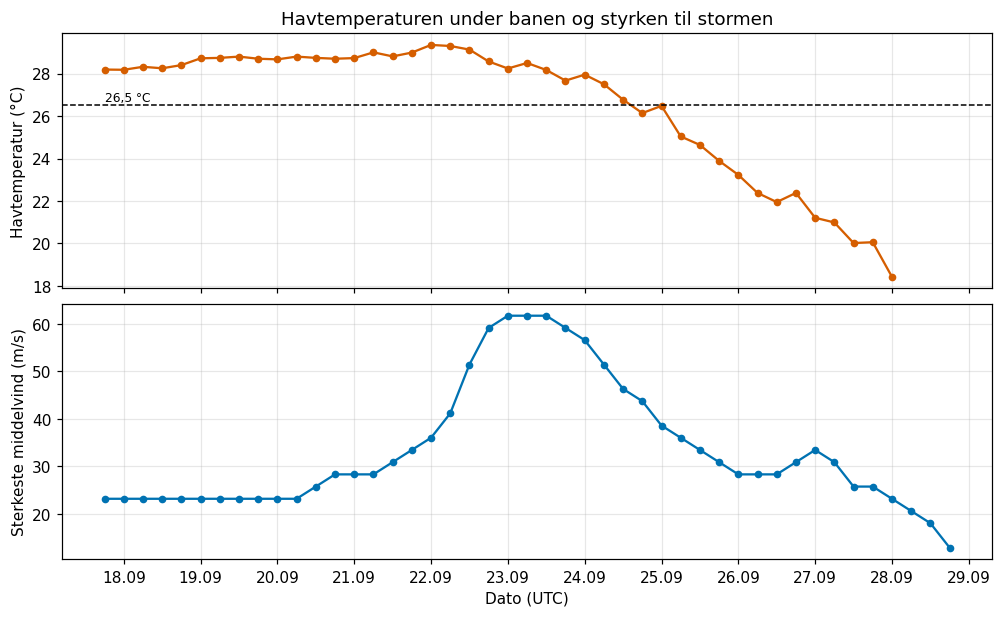

In [8]:
if sst is not None:
    dag = (bane.tid_utc.dt.floor("D") - pd.Timedelta(days=2)).clip(
        lower=pd.Timestamp(sst.time.values[0]))
    bane["sst"] = sst.sel(time=xr.DataArray(dag.values, dims="punkt"),
                          lat=xr.DataArray(bane.lat.values, dims="punkt"),
                          lon=xr.DataArray(bane.lon.values, dims="punkt"),
                          method="nearest").values

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True,
                                 constrained_layout=True)
    a1.plot(bane.tid_utc, bane.sst, "-o", color="#D55E00", ms=4)
    a1.axhline(26.5, color="k", ls="--", lw=1)
    a1.text(bane.tid_utc.min(), 26.7, "26,5 °C", fontsize=8)
    a1.set_ylabel("Havtemperatur (°C)")
    a1.set_title("Havtemperaturen under banen og styrken til stormen")
    a2.plot(bane.tid_utc, bane.vind_ms, "-o", color="#0072B2", ms=4)
    a2.set_ylabel("Sterkeste middelvind (m/s)")
    a2.set_xlabel("Dato (UTC)")
    datoakse(a2); komma(a1); komma(a2)
    plt.show()

**Oppgaver**
1. Når krysset Gabrielle 26,5 °C-linjen og kom over kaldere vann?
2. Begynte stormen å svekke seg før eller etter at den kom over kaldere vann? Kan havtemperaturen alene forklare svekkelsen? Hold på svaret til Del 3.

✏️ **Svar**

*Skriv svaret ditt her.*

### 2c Det kalde kjølvannet

> 📘 **Begrep** Et **avvik** er forskjellen mellom en målt verdi og en referanseverdi. Et annet ord for det samme er **anomali**. Her bruker vi havtemperaturen før stormen som referanse, så avviket viser hvor mye havet er blitt kaldere eller varmere.

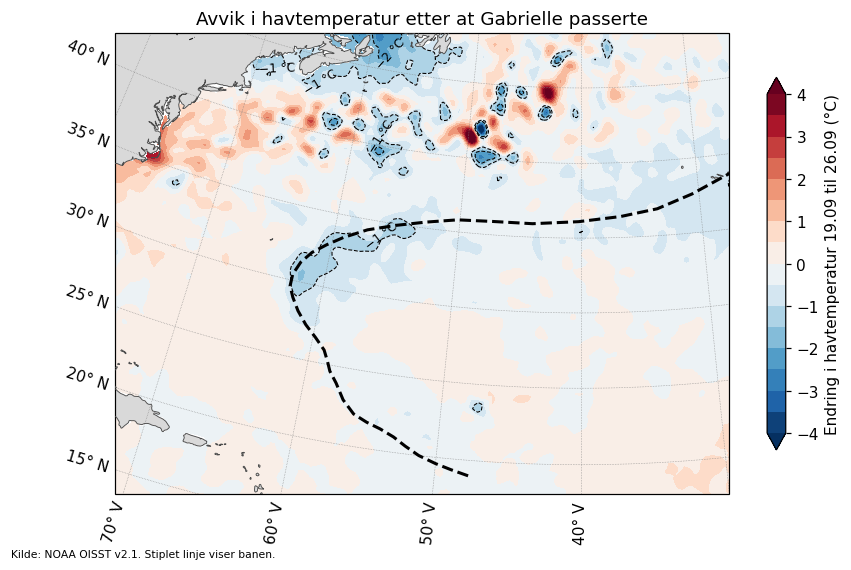

Største avkjøling −5,6 °C ved 41,9° N, 48,9° V


In [9]:
FOR = "2025-09-19"      # 🔧
ETTER = "2025-09-26"    # 🔧

if sst is not None:
    diff = sst.sel(time=ETTER, method="nearest") - sst.sel(time=FOR, method="nearest")
    fig = plt.figure(figsize=(9, 5.5))
    ax = plt.axes(projection=PROJ)
    kart(ax, [-72, -30, 18, 45])
    cf = ax.contourf(diff.lon, diff.lat, diff, levels=np.arange(-4, 4.5, 0.5),
                     cmap="RdBu_r", norm=TwoSlopeNorm(0), extend="both", transform=PC)
    cs = ax.contour(diff.lon, diff.lat, diff, levels=[-2, -1], colors="k",
                    linewidths=0.7, transform=PC)
    ax.clabel(cs, fmt=lambda v: f"{v:g} °C".replace("-", "−"), fontsize=8)
    ax.plot(bane.lon, bane.lat, color="k", lw=2, ls="--", transform=PC, zorder=4)
    fig.colorbar(cf, ax=ax, shrink=0.8,
                 label=f"Endring i havtemperatur {FOR[8:]}.09 til {ETTER[8:]}.09 (°C)")
    ax.set_title("Avvik i havtemperatur etter at Gabrielle passerte")
    fig.text(0.02, 0.01, "Kilde: NOAA OISST v2.1. Stiplet linje viser banen.", fontsize=7)
    plt.show()

    utsnitt = diff.sel(lat=slice(20, 42), lon=slice(-70, -40))
    i = utsnitt.argmin(dim=["lat", "lon"])
    p = utsnitt.isel(i)
    print(f"Største avkjøling {float(p):.1f} °C ved {float(p.lat):.1f}° N, "
          f"{abs(float(p.lon)):.1f}° V".replace(".", ",").replace("-", "−"))

**Oppgaver**
1. Hvor mye ble havet avkjølt der avkjølingen var størst? Ligger området til høyre eller til venstre for banen sett i bevegelsesretningen?
2. Forklar to prosesser som kan kjøle ned havoverflaten under en orkan. Tenk på hva sterk vind gjør med blandingslaget, og hva som skjer med vannet under sentrum av en syklon på den nordlige halvkule (Ekman-pumping).
3. Hvorfor er det kalde kjølvannet et større problem for en orkan som beveger seg sakte enn for en som beveger seg fort?

✏️ **Svar**

*Skriv svaret ditt her.*

---
## ☕ Pause (10 min)

---
## Del 3 Fra orkan til ekstratropisk storm (30 min)

> 📘 **Begrep** **Ekstratropisk overgang** er når en tropisk syklon mister den varme kjernen og blir et lavtrykk av samme type som lavtrykkene vi får i Norge. Energien kommer da mindre fra havet og mer fra temperaturkontraster mellom varm og kald luft. Vindfeltet blir større og mer skjevt, og stormen kan bli sterkere igjen.

### 3a Trykk og temperatur på tre tidspunkter
Kartene viser lufttrykket redusert til havnivå (svarte isobarer hver 5. hPa) og temperaturen i 850 hPa, omtrent 1,5 km over havet (farger).

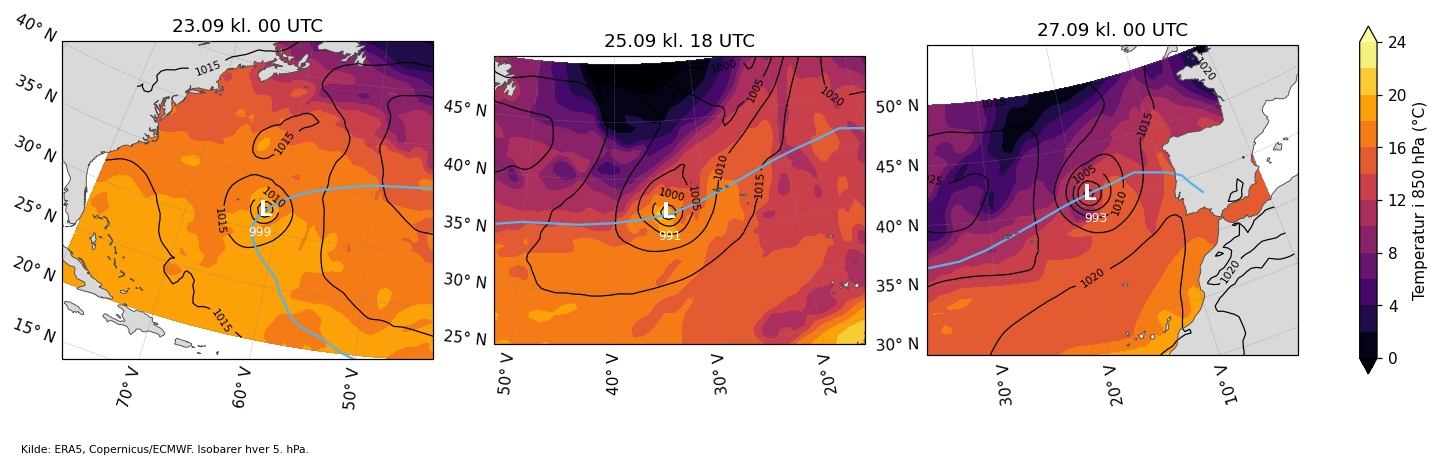

In [10]:
TIDER = ["2025-09-23T00", "2025-09-25T18", "2025-09-27T00"]   # 🔧

if era5 is not None and era5p is not None:
    fig, akser = plt.subplots(1, 3, figsize=(13, 4.6), subplot_kw={"projection": PROJ},
                              constrained_layout=True)
    for ax, t in zip(akser, TIDER):
        b = bane.iloc[(bane.tid_utc - pd.Timestamp(t)).abs().argmin()]
        # Utsnitt rundt sentrum, innenfor området vi har data for
        kart(ax, [max(b.lon - 18, -80), min(b.lon + 18, 0),
                  max(b.lat - 12, 20), min(b.lat + 12, 50)])
        p = era5.msl.sel(time=t, method="nearest") / 100
        T = era5p.t.sel(time=t, nivaa=850, method="nearest") - 273.15
        cf = ax.contourf(T.lon, T.lat, T, levels=np.arange(0, 26, 2), cmap="inferno",
                         extend="both", transform=PC)
        cs = ax.contour(p.lon, p.lat, p, levels=np.arange(940, 1040, 5), colors="k",
                        linewidths=0.8, transform=PC)
        ax.clabel(cs, fmt="%d", fontsize=7)
        # L ved laveste trykk nær banen
        omr = p.sel(lat=slice(b.lat - 5, b.lat + 5), lon=slice(b.lon - 5, b.lon + 5))
        m = omr.where(omr == omr.min(), drop=True)
        ax.text(float(m.lon[0]), float(m.lat[0]), "L", color="w", fontsize=14,
                weight="bold", ha="center", va="center", transform=PC, zorder=6)
        ax.text(float(m.lon[0]), float(m.lat[0]) - 2.5, f"{float(omr.min()):.0f}",
                color="w", fontsize=8, ha="center", transform=PC, zorder=6)
        ax.plot(bane.lon, bane.lat, color="#56B4E9", lw=1.5, transform=PC)
        ax.set_title(f"{pd.Timestamp(t):%d.%m kl. %H} UTC")
    fig.colorbar(cf, ax=akser, shrink=0.7, label="Temperatur i 850 hPa (°C)")
    fig.text(0.01, 0.0, "Kilde: ERA5, Copernicus/ECMWF. Isobarer hver 5. hPa.", fontsize=7)
    plt.show()

**Oppgaver**
1. Sammenlign trykkfeltet rundt L på de tre kartene. Når er stormen liten og symmetrisk, og når blir den større og mer skjev?
2. Se på temperaturen i 850 hPa. På hvilket kart ser du en tydelig grense mellom varm og kald luft nær lavtrykket? Hva kaller vi en slik grense?
3. Bruk kartene til å forklare at stormen kunne bli sterkere igjen 27. september selv om havet under den var kaldt.

✏️ **Svar**

*Skriv svaret ditt her.*

### 3b Vindskjær

> 📘 **Begrep** **Vindskjær** er forskjellen i vind mellom to høyder. Her bruker vi forskjellen mellom 200 hPa (omtrent 12 km) og 850 hPa. Sterkt vindskjær vipper toppen av stormen bort fra bunnen, slik at varmemaskinen ikke henger sammen lenger. Over omtrent 10 m/s er vindskjæret ugunstig for tropiske sykloner.

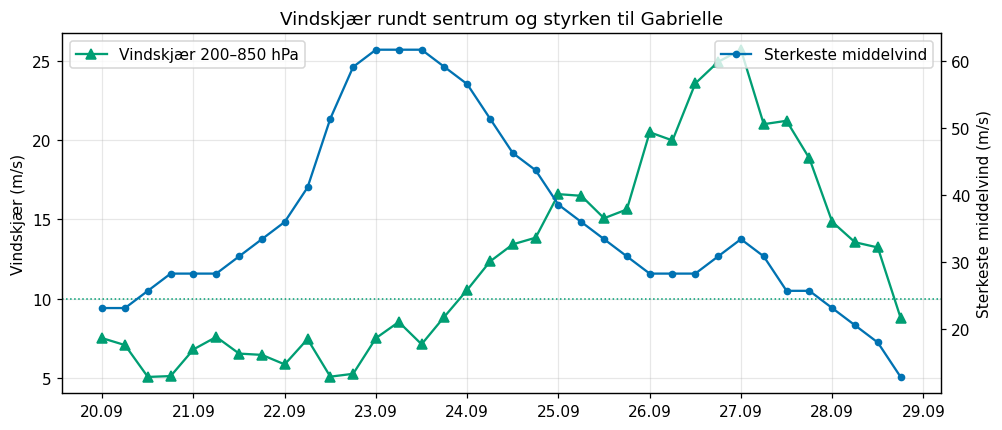

In [11]:
BOKS = 5          # 🔧 grader rundt sentrum som vi tar gjennomsnittet over

if era5p is not None:
    rader = []
    tmin, tmax = pd.Timestamp(era5p.time.values[0]), pd.Timestamp(era5p.time.values[-1])
    for _, r in bane[(bane.tid_utc >= tmin) & (bane.tid_utc <= tmax)].iterrows():
        omr = era5p.sel(time=r.tid_utc, lat=slice(r.lat - BOKS, r.lat + BOKS),
                        lon=slice(r.lon - BOKS, r.lon + BOKS)).mean(["lat", "lon"])
        du = float(omr.u.sel(nivaa=200) - omr.u.sel(nivaa=850))
        dv = float(omr.v.sel(nivaa=200) - omr.v.sel(nivaa=850))
        rader.append((r.tid_utc, np.hypot(du, dv), r.vind_ms))
    skjaer = pd.DataFrame(rader, columns=["tid_utc", "skjaer_ms", "vind_ms"])

    fig, a1 = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
    a1.plot(skjaer.tid_utc, skjaer.skjaer_ms, "-^", color="#009E73", label="Vindskjær 200–850 hPa")
    a1.axhline(10, color="#009E73", ls=":", lw=1)
    a1.set_ylabel("Vindskjær (m/s)")
    a2 = a1.twinx()
    a2.plot(skjaer.tid_utc, skjaer.vind_ms, "-o", color="#0072B2", ms=4, label="Sterkeste middelvind")
    a2.set_ylabel("Sterkeste middelvind (m/s)")
    a2.grid(False)
    a1.legend(loc="upper left"); a2.legend(loc="upper right")
    datoakse(a1); komma(a1); komma(a2)
    a1.set_title("Vindskjær rundt sentrum og styrken til Gabrielle")
    plt.show()

**Oppgaver**
1. Hvordan var vindskjæret mens Gabrielle intensiverte raskt? Hvordan endret det seg 23. og 24. september?
2. Gå tilbake til svaret ditt i 2b. Forklar svekkelsen med både havtemperatur og vindskjær.

✏️ **Svar**

*Skriv svaret ditt her.*

### 3c Gabrielle treffer Asorene
Tabellen nedenfor viser målinger fra værstasjonene på Asorene 26. september. Stasjonene måler middelvind over **10 minutter**, mens banedataene bruker middelvind over **1 minutt**.

In [12]:
st = stasjoner.copy()
st["middelvind_ms"] = (st.middelvind_10min_kt * KT_TIL_MS).round(1)
st["vindkast_ms"] = (st.vindkast_kt * KT_TIL_MS).round(1)
st["vindkastfaktor"] = (st.vindkast_kt / st.middelvind_10min_kt).round(2)
st[["stasjon", "hoyde_moh", "min_trykk_hPa", "tid_min_trykk_utc",
    "middelvind_ms", "vindkast_ms", "vindkastfaktor", "nedbor_mm"]]

,stasjon,hoyde_moh,min_trykk_hPa,tid_min_trykk_utc,middelvind_ms,vindkast_ms,vindkastfaktor,nedbor_mm
0,Flores,28,1000.4,2025-09-26 17:00:00,11.3,17.0,1.50,22.2
1,Faial (08505),41,986.4,2025-09-26 04:00:00,14.9,30.9,2.07,29.6
2,Faial (08506),55,984.4,2025-09-26 04:00:00,21.6,42.7,1.98,17.6
3,Pico,39,985.7,2025-09-26 04:00:00,11.8,24.2,2.04,28.2
4,Graciosa,25,988.6,2025-09-26 05:00:00,22.1,32.4,1.47,60.9
5,Terceira,90,984.5,2025-09-26 07:00:00,17.0,33.4,1.97,8.3
6,São Miguel,76,996.5,2025-09-26 08:00:00,9.8,28.8,2.95,1.3


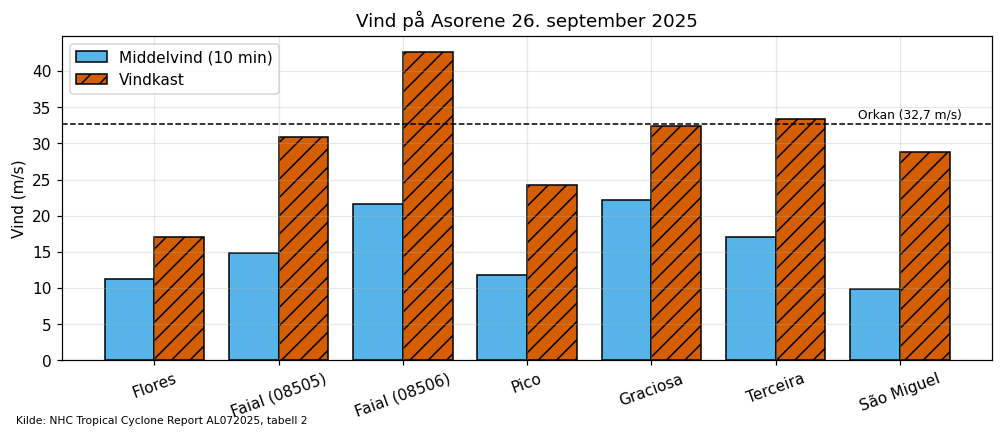

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
x = np.arange(len(st))
ax.bar(x - 0.2, st.middelvind_ms, 0.4, color="#56B4E9", edgecolor="k", label="Middelvind (10 min)")
ax.bar(x + 0.2, st.vindkast_ms, 0.4, color="#D55E00", edgecolor="k", hatch="//", label="Vindkast")
ax.axhline(32.7, color="k", ls="--", lw=1)
ax.text(len(st) - 0.5, 33.5, "Orkan (32,7 m/s)", ha="right", fontsize=8)
ax.set_xticks(x, st.stasjon, rotation=20)
ax.set_ylabel("Vind (m/s)")
ax.set_title("Vind på Asorene 26. september 2025")
ax.legend(loc="upper left")
komma(ax)
fig.text(0.01, 0.0, "Kilde: NHC Tropical Cyclone Report AL072025, tabell 2", fontsize=7)
plt.show()

**Oppgaver**
1. Hvilke stasjoner fikk vindkast av orkanstyrke? Var det noen som fikk orkan i middelvind?
2. Vindkastene er mye sterkere enn middelvinden. Forklar hvorfor.
3. På Santa Barbara-fjellet på Terceira, 1010 meter over havet, ble det målt vindkast på 100 knop (51 m/s). Hvorfor er vinden sterkere der enn på stasjonene nær havnivå?
4. Hvorfor er en middelvind over 10 minutter alltid litt lavere enn sterkeste middelvind over 1 minutt?

✏️ **Svar**

*Skriv svaret ditt her.*

### 3d Hvor fort gikk stormen?
Laveste trykk kom til ulik tid på ulike øyer. Vi kan bruke det til å anslå hvor fort lavtrykket flyttet seg.

In [14]:
FRA = "Faial (08506)"     # 🔧
TIL = "São Miguel"        # 🔧

a = st.set_index("stasjon").loc[FRA]
b = st.set_index("stasjon").loc[TIL]
d_km = avstand_km(a.lat_ca, a.lon_ca, b.lat_ca, b.lon_ca)
t_h = (b.tid_min_trykk_utc - a.tid_min_trykk_utc).total_seconds() / 3600
print(f"Avstand {d_km:.0f} km, tidsforskjell {t_h:.0f} timer")
if t_h > 0:
    print(f"Anslått forflytningsfart {d_km / t_h:.0f} km/h = {d_km / t_h / 3.6:.0f} m/s")

# Til sammenligning: farten mellom banepunktene 26. september
d = bane[(bane.tid_utc >= "2025-09-26") & (bane.tid_utc <= "2025-09-26 12:00")]
bt = avstand_km(d.lat.values[:-1], d.lon.values[:-1], d.lat.values[1:], d.lon.values[1:]) / 6
print("Fart fra banedataene (km/h):", np.round(bt).astype(int))

Avstand 278 km, tidsforskjell 4 timer
Anslått forflytningsfart 70 km/h = 19 m/s
Fart fra banedataene (km/h): [49 51]


**Oppgaver**
1. Sammenlign anslaget ditt med farten fra banedataene. Hvorfor blir de ikke helt like? Tenk på hvor stasjonene ligger i forhold til banen.
2. Hvorfor gir et lavtrykk som beveger seg fort, sterkere vind på den ene siden av banen enn på den andre?

✏️ **Svar**

*Skriv svaret ditt her.*

---
## Del 4 Oppsummering (20 min)

Gå tilbake til hovedspørsmålet og hypotesen din fra starten.

> 🌀 Hvorfor ble Gabrielle så sterk så raskt, hvorfor svekket den seg igjen, og hvordan kunne Asorene få orkankast fra en storm som ikke lenger var en orkan?

Skriv et svar på 150–250 ord. Bruk minst **tre konkrete tall** fra figurene og tabellene ovenfor, og vis til hvilken figur tallene kommer fra. Skriv også om hypotesen din stemte.

✏️ **Svar**

*Gabrielle ble sterk fordi …*

**Refleksjon**
Hvilke usikkerheter er det i dataene du har brukt? Tenk på forskjellen mellom en reanalyse (ERA5), satellittmålinger (OISST) og værstasjoner, og på hvordan sterkeste middelvind i en orkan blir bestemt.

✏️ **Svar**

*Skriv svaret ditt her.*

---
## Fordypning A Havet under overflaten (Argo)

Argo-bøyer driver rundt i havet og måler temperatur og salinitet fra 2000 meters dyp til overflaten omtrent hvert tiende døgn. Her ser vi etter en bøye som målte både før og etter at Gabrielle passerte.

Mulige bøyer: 1902360, 1902438, 3902683, 4902322, 4902503, 4902927, 4903043, 4903258, 4903456, 6901997, 6904126, 6990501


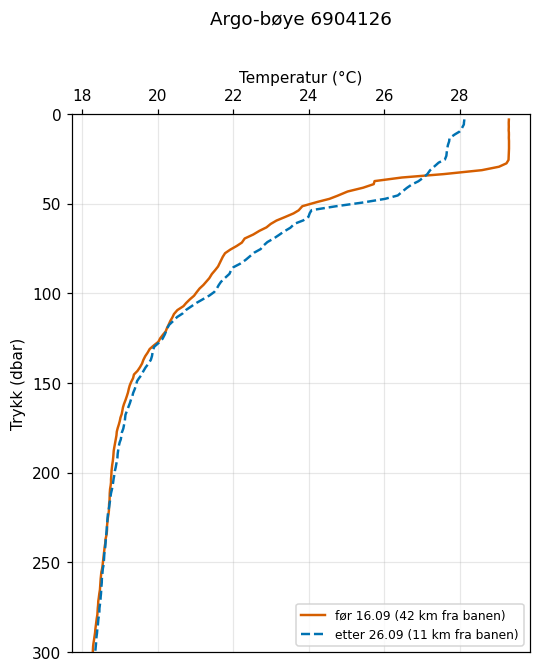

In [15]:
MAKS_AVSTAND = 300     # 🔧 km fra banen
BOYE = None            # 🔧 skriv inn et bøyenummer for å velge en annen bøye

if finnes("argo_gabrielle.csv"):
    argo = pd.read_csv(DATA / "argo_gabrielle.csv", parse_dates=["TIME"])
    prof = (argo.groupby(["PLATFORM_NUMBER", "CYCLE_NUMBER"])
                .agg(tid=("TIME", "first"), lat=("LATITUDE", "first"),
                     lon=("LONGITUDE", "first")).reset_index())

    def naermeste(r):
        d = avstand_km(r.lat, r.lon, bane.lat.values, bane.lon.values)
        i = int(np.argmin(d))
        return pd.Series({"avstand_km": d[i], "passering": bane.tid_utc.iloc[i]})

    prof = prof.join(prof.apply(naermeste, axis=1))
    prof["fase"] = np.where(prof.tid < prof.passering, "før", "etter")
    kand = (prof[prof.avstand_km < MAKS_AVSTAND]
            .groupby("PLATFORM_NUMBER").filter(lambda g: set(g.fase) == {"før", "etter"}))
    if kand.empty:
        print("Fant ingen bøye med målinger både før og etter. Øk MAKS_AVSTAND.")
    else:
        print("Mulige bøyer:", ", ".join(str(int(n)) for n in sorted(kand.PLATFORM_NUMBER.unique())))
        nr = BOYE or kand.sort_values("avstand_km").PLATFORM_NUMBER.iloc[0]
        k = kand[kand.PLATFORM_NUMBER == nr]
        valgt = [k[k.fase == "før"].sort_values("tid").iloc[-1],
                 k[k.fase == "etter"].sort_values("tid").iloc[0]]

        fig, ax = plt.subplots(figsize=(4.8, 6), constrained_layout=True)
        for r, farge, ls in zip(valgt, ["#D55E00", "#0072B2"], ["-", "--"]):
            p = argo[(argo.PLATFORM_NUMBER == r.PLATFORM_NUMBER)
                     & (argo.CYCLE_NUMBER == r.CYCLE_NUMBER)].sort_values("PRES")
            ax.plot(p.TEMP, p.PRES, color=farge, ls=ls, lw=1.6,
                    label=f"{r.fase} {r.tid:%d.%m} ({r.avstand_km:.0f} km fra banen)")
        ax.invert_yaxis()
        ax.set_ylim(300, 0)
        ax.xaxis.set_label_position("top"); ax.xaxis.tick_top()
        ax.set_xlabel("Temperatur (°C)"); ax.set_ylabel("Trykk (dbar)")
        ax.legend(loc="lower right", fontsize=8)
        ax.set_title(f"Argo-bøye {nr}", pad=30)
        komma(ax, x=True)
        plt.show()

**Oppgaver**
1. Hvordan endret temperaturen i de øverste 100 meterne seg etter at stormen passerte?
2. Ble blandingslaget dypere eller grunnere? Hvordan ser du det i profilen?
3. Husk at 1 dbar er omtrent 1 meter. Ned til hvilket dyp merket havet at stormen hadde vært der?

✏️ **Svar**

*Skriv svaret ditt her.*

## Fordypning B To orkaner samtidig

Mens Gabrielle var på vei mot Asorene, ble orkanen Humberto dannet lenger sør og vest. Humberto ble senere en kategori 5-orkan.

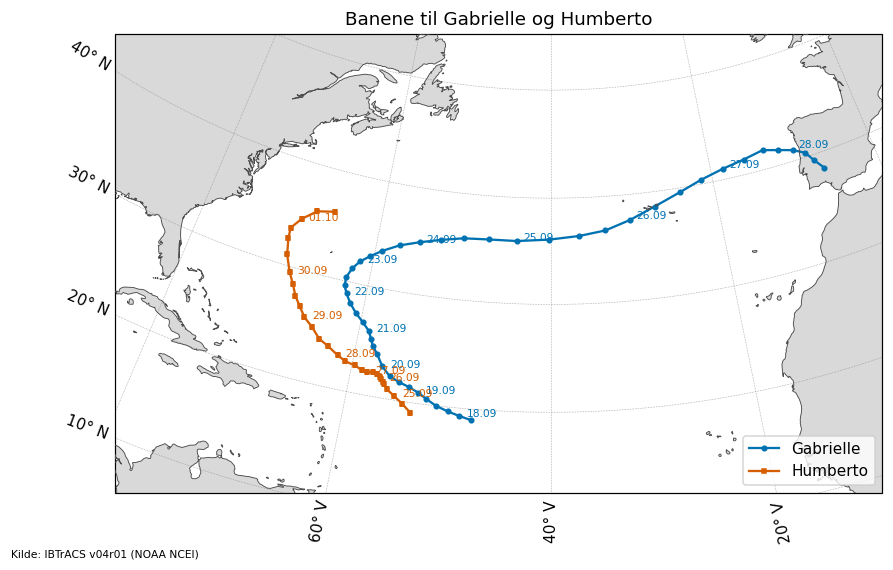

Avstand mellom sentrene 25.09 kl. 00 UTC 2051 km


In [16]:
if finnes("humberto_bane.csv"):
    hum = pd.read_csv(DATA / "humberto_bane.csv", parse_dates=["tid_utc"])
    fig = plt.figure(figsize=(9, 5.5))
    ax = plt.axes(projection=PROJ)
    kart(ax, [-80, -10, 12, 50])
    for df, navn, farge, merke in [(bane, "Gabrielle", "#0072B2", "o"),
                                   (hum, "Humberto", "#D55E00", "s")]:
        ax.plot(df.lon, df.lat, color=farge, lw=1.5, marker=merke, ms=3,
                transform=PC, label=navn)
        for _, r in df[df.tid_utc.dt.hour == 0].iterrows():
            ax.text(r.lon + 0.8, r.lat, f"{r.tid_utc:%d.%m}", fontsize=7,
                    color=farge, transform=PC)
    ax.legend(loc="lower right")
    ax.set_title("Banene til Gabrielle og Humberto")
    fig.text(0.02, 0.01, "Kilde: IBTrACS v04r01 (NOAA NCEI)", fontsize=7)
    plt.show()

    t = pd.Timestamp("2025-09-25 00:00")      # 🔧
    g = bane[bane.tid_utc == t]; h = hum[hum.tid_utc == t]
    if len(g) and len(h):
        print(f"Avstand mellom sentrene {t:%d.%m kl. %H} UTC "
              f"{avstand_km(g.lat.values[0], g.lon.values[0], h.lat.values[0], h.lon.values[0]):.0f} km")

**Oppgaver**
1. Hvor langt fra hverandre var sentrene på det tidspunktet du valgte?
2. Sammenlign banene. Gikk Humberto over området der Gabrielle hadde kjølt ned havet (se 2c)? Hva ville det i så fall betydd for Humberto?

✏️ **Svar**

*Skriv svaret ditt her.*